# Modul 3 - Diagnosis dan Penanganan Overfitting

**Pokok Bahasan**
1. Menciptakan Kondisi Overfitting
2. Penanganan dengan L2, Dropout, dan Early Stopping
3. Analisis Komparasi Kinerja dan Inferensi Akhir

Pada modul ini, akan dilakukan kesengajaan untuk menciptakan kondisi Overfitting. Proses yang berjalan akan memaksa model kompleks menghafal dataset kecil. Selanjutnya, modul akan mengarahkan setiap mahasiswa untuk mempelajari cara merawat model yang "sakit" tersebut menggunakan tiga teknik fundamental: Dropout, Regularisasi L2 (Weight Decay), dan Early Stopping.

## 1. Menciptakan Kondisi Overfitting

Kondisi ini terjadi ketika: Kapasitas model (jumlah layer dan parameter) JAUH lebih besar daripada kompleksitas data, sehingga model menghafal pola noise latih secara membabi-buta.

In [1]:
# Library untuk penerapan deep learning berbasis pytorch
import torch
import torch.nn as nn
import torch.optim as optim
# Library yang digunakan untuk membuat dataset tiruan (sintetis) secara acak dan preprocessing
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
# Library untuk visualisasi data
import matplotlib.pyplot as plt

In [2]:
# Membuat data tabular sintetik berukuran KECIL (300 data) tapi penuh noise
X, y = make_classification(n_samples=300, n_features=20, n_informative=5, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

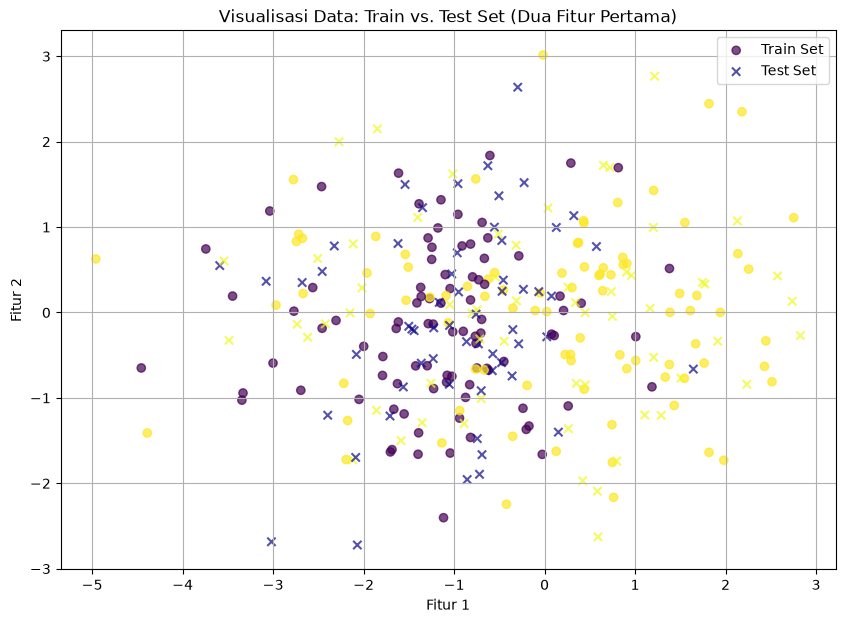

In [3]:
# Visualisasi titik data dengan perbedaan warna antara train set dan test set
plt.figure(figsize=(10, 7))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis',
            label='Train Set', alpha=0.7)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='plasma', marker='x',
            label='Test Set', alpha=0.7)
plt.title('Visualisasi Data: Train vs. Test Set (Dua Fitur Pertama)')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend()
plt.grid(True)
plt.show()

In [4]:
# Konversi Tensor
X_tr = torch.FloatTensor(X_train)
y_tr = torch.FloatTensor(y_train).view(-1, 1)
X_te = torch.FloatTensor(X_test)
y_te = torch.FloatTensor(y_test).view(-1, 1)

In [5]:
# Membuat Arsitektur TERLALU BESAR (4 layer tebal berturut-turut)
model_overfit = nn.Sequential(
    nn.Linear(20, 256), nn.ReLU(),
    nn.Linear(256, 256), nn.ReLU(),
    nn.Linear(256, 256), nn.ReLU(),
    nn.Linear(256, 1)
)

In [6]:
# Inisialisasi dan Proses Pelatihan Model yang Cenderung Overfitting
criterion_of = nn.BCEWithLogitsLoss()
optimizer_of = optim.Adam(model_overfit.parameters(), lr=0.005)
of_train_loss, of_test_loss = [], []

print("Melatih Model yang Rentan Overfitting...")
for epoch in range(400):
  model_overfit.train()
  optimizer_of.zero_grad()
  loss_t = criterion_of(model_overfit(X_tr), y_tr)
  loss_t.backward()
  optimizer_of.step()

  # Hitung test loss
  with torch.no_grad():
    model_overfit.eval()
    loss_val = criterion_of(model_overfit(X_te), y_te)

  of_train_loss.append(loss_t.item())
  of_test_loss.append(loss_val.item())

Melatih Model yang Rentan Overfitting...


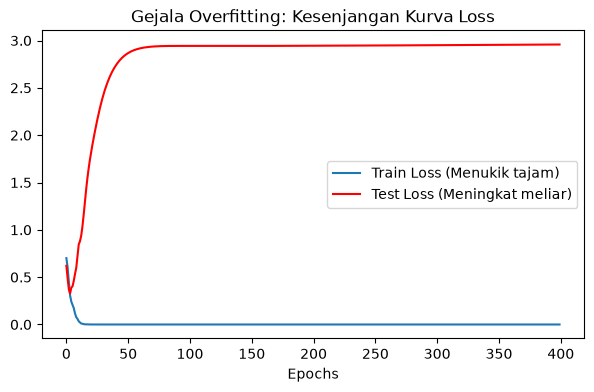

Diagnosis: Model gagal generalisasi.
Saat Train Loss habis, Test Loss justru naik karena menghafal noise!


In [7]:
# Visualisasi Bukti Overfitting
plt.figure(figsize=(7, 4))
plt.plot(of_train_loss, label='Train Loss (Menukik tajam)')
plt.plot(of_test_loss, label='Test Loss (Meningkat meliar)', color='red')
plt.title('Gejala Overfitting: Kesenjangan Kurva Loss')
plt.xlabel('Epochs')
plt.legend()
plt.show()

print("Diagnosis: Model gagal generalisasi.")
print("Saat Train Loss habis, Test Loss justru naik karena menghafal noise!")

## 2. Penanganan dengan L2, Dropout, dan Early Stopping

Pada modul ini akan dicoba untuk menyembuhkan arsitektur yang sama dengan penggunaan tiga strategi:
1. **L2 Regularization (Weight Decay):** Menambahkan penalti pada ukuran bobot. Di PyTorch, cukup tambahkan argument `weight_decay` pada Optimizer.
2. **Dropout:** Mematikan sebagian neuron secara acak (misal 50%) selama iterasi. Ini mencegah ko-adaptasi (neuron terlalu bergantung pada neuron tetangganya). Disisipkan setelah fungsi aktivasi.
3. **Early Stopping:** Menghentikan perulangan (For Loop) secara paksa jika Test Loss tidak kunjung membaik setelah batas kesabaran (Patience) terlewati.

In [8]:
# LANGKAH 1: Menambahkan DROPOUT pada Arsitektur
# Nilai prob dropout 0.5 yang mengartikan melakukan non aktif 50% neuron secara acak
model_healed = nn.Sequential(
    nn.Linear(20, 256), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(256, 256), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(256, 256), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(256, 1)
)

In [9]:
# LANGKAH 2: Menambahkan REGULARISASI L2 (Weight Decay)
# Parameter weight_decay=1e-3 akan memberikan penalti L2
optimizer_healed = optim.Adam(model_healed.parameters(), lr=0.005, weight_decay=1e-3)
heal_train_loss, heal_test_loss = [], []

# LANGKAH 3: Menerapkan Logika EARLY STOPPING pada siklus pelatihan model
best_test_loss = float('inf')
patience = 20
counter = 0
best_epoch = 0

In [10]:
print("Melatih Model dengan Proteksi Penuh...")
for epoch in range(400):
  # Mode Train mengaktifkan algoritma pengacakan Dropout
  model_healed.train()
  optimizer_healed.zero_grad()
  loss_t = criterion_of(model_healed(X_tr), y_tr)
  loss_t.backward()
  optimizer_healed.step()

  # Mode Eval MEMATIKAN Dropout otomatis. Seluruh neuron digunakan untuk real test.
  model_healed.eval()
  with torch.no_grad():
    loss_val = criterion_of(model_healed(X_te), y_te)

  heal_train_loss.append(loss_t.item())
  heal_test_loss.append(loss_val.item())

  # Cek Early Stopping
  if loss_val.item() < best_test_loss:
    best_test_loss = loss_val.item()
    best_epoch = epoch
    counter = 0 # Reset proses perhitungan toleransi jika loss membaik
  else:
    counter += 1

  if counter >= patience:
    print(f"EARLY STOPPING terpicu pada epoch {epoch}!")
    print(f"Performa terbaik di epoch {best_epoch}.")
    break

Melatih Model dengan Proteksi Penuh...
EARLY STOPPING terpicu pada epoch 25!
Performa terbaik di epoch 5.


## 3. Analisis Komparasi Kinerja dan Inferensi Akhir

Langkah selanjutnya yaitu membandingkan secara visual antara model yang dibiarkan tanpa penerapan strategi penanganan overfitting dengan model yang telah menerapkan beberapa strategi.

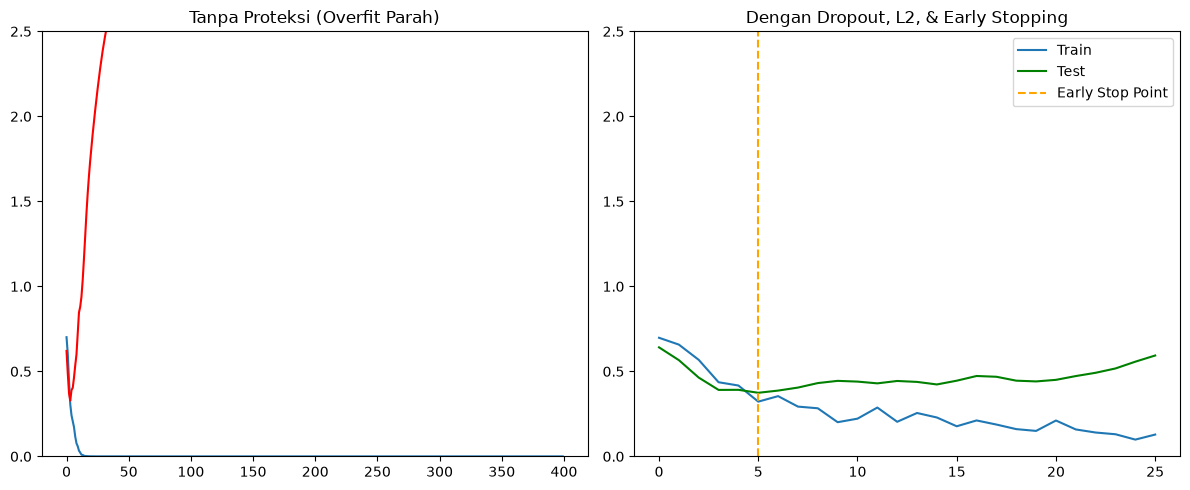

In [11]:
# Visualisasi Perbandingan
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(of_train_loss, label='Train')
plt.plot(of_test_loss, label='Test', color='red')
plt.title('Tanpa Proteksi (Overfit Parah)')
plt.ylim(0, 2.5) # Batasi y axis agar mudah diamati

plt.subplot(1, 2, 2)
plt.plot(heal_train_loss, label='Train')
plt.plot(heal_test_loss, label='Test', color='green')
plt.axvline(x=best_epoch, color='orange', linestyle='--', label='Early Stop Point')
plt.title('Dengan Dropout, L2, & Early Stopping')
plt.ylim(0, 2.5)
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
# Performance Metrics Comparison (Test Set)
def get_accuracy(model_obj):
  model_obj.eval()
  with torch.no_grad():
    probs = torch.sigmoid(model_obj(X_te))
    preds = (probs >= 0.5).float()
    return accuracy_score(y_te.numpy(), preds.numpy())

acc_overfit = get_accuracy(model_overfit)
acc_healed = get_accuracy(model_healed)

print(f"Akurasi Test - Model Overfit (Menghafal noise) : {acc_overfit * 100:.1f}%")
print(f"Akurasi Test - Model Terselamatkan (Generalisasi) : {acc_healed * 100:.1f}%")

Akurasi Test - Model Overfit (Menghafal noise) : 83.3%
Akurasi Test - Model Terselamatkan (Generalisasi) : 84.2%


In [13]:
# Contoh Inferensi (Pengujian Output) terhadap 10 data pada test set
print("\n--- Contoh Inferensi Data Baru ---")
data_baru = X_te[0:10]
label_asli = y_te[0:10]

model_healed.eval()
with torch.no_grad():
  skor_mentah = model_healed(data_baru)
  probabilitas = torch.sigmoid(skor_mentah)
  prediksi_final = (probabilitas >= 0.5).int()

for i in range(10):
  print(f"Data {i+1}")
  print(f"Label Asli: {int(label_asli[i].item())}")
  print(f"Prediksi AI: {prediksi_final[i].item()}")
  print(f"(Probabilitas: {probabilitas[i].item()*100:.1f}%)\n")


--- Contoh Inferensi Data Baru ---
Data 1
Label Asli: 0
Prediksi AI: 1
(Probabilitas: 58.9%)

Data 2
Label Asli: 0
Prediksi AI: 0
(Probabilitas: 0.1%)

Data 3
Label Asli: 1
Prediksi AI: 1
(Probabilitas: 100.0%)

Data 4
Label Asli: 1
Prediksi AI: 1
(Probabilitas: 92.2%)

Data 5
Label Asli: 1
Prediksi AI: 1
(Probabilitas: 100.0%)

Data 6
Label Asli: 1
Prediksi AI: 1
(Probabilitas: 100.0%)

Data 7
Label Asli: 0
Prediksi AI: 0
(Probabilitas: 0.1%)

Data 8
Label Asli: 0
Prediksi AI: 0
(Probabilitas: 0.2%)

Data 9
Label Asli: 1
Prediksi AI: 1
(Probabilitas: 96.5%)

Data 10
Label Asli: 1
Prediksi AI: 1
(Probabilitas: 96.3%)

